# Facial Emotion Recognition — Kaggle Training Notebook (RAF-DB)

Trains a CNN on RAF-DB across **7 emotion classes**.

**Improvements over previous run:**
- RGB colour images instead of grayscale (retains colour/lighting cues)
- Deeper 4-block custom CNN
- Class weights to handle class imbalance (fear/disgust underrepresented)

**Output:** `facialemotionmodel.h5` saved to `/kaggle/working/`

### Before running:
1. Settings (right panel) → **Accelerator** → **GPU T4 x2**
2. Add your RAF-DB dataset via the **Data** tab on the right
3. Update `DATASET_NAME` in Step 1 to match your dataset slug
4. Click **Save Version** → **Save & Run All (Commit)** to train offline

## Step 1 — Configuration

In [1]:
import os

# ── UPDATE THIS to match your dataset slug shown in the Data tab ─────────────
DATASET_NAME = 'RAF-DB DATASET'  # <-- change this

# Image settings
IMG_SIZE    = 48        # spatial size (pixels)
CHANNELS    = 3         # 3 = RGB colour, 1 = grayscale
COLOR_MODE  = 'rgb'     # matches CHANNELS
BATCH_SIZE  = 64

# Paths
INPUT_DIR  = f'/kaggle/input/datasets/shuvoalok/raf-db-dataset'
OUTPUT_DIR = '/kaggle/working'

# Auto-detect RAF-DB root folder
TRAIN_DIR = None
TEST_DIR  = None
TRAIN_CSV = None
TEST_CSV  = None

for subfolder in ['DATASET', 'dataset', '']:
    base = os.path.join(INPUT_DIR, subfolder) if subfolder else INPUT_DIR
    candidate_train = os.path.join(base, 'train')
    if os.path.exists(candidate_train):
        TRAIN_DIR = candidate_train
        TEST_DIR  = os.path.join(base, 'test')
        TRAIN_CSV = os.path.join(base, 'train_labels.csv')
        TEST_CSV  = os.path.join(base, 'test_labels.csv')
        TRAIN_CSV = TRAIN_CSV if os.path.exists(TRAIN_CSV) else None
        TEST_CSV  = TEST_CSV  if os.path.exists(TEST_CSV)  else None
        break

print('Train dir :', TRAIN_DIR, '— exists:', os.path.exists(TRAIN_DIR))
print('Test  dir :', TEST_DIR,  '— exists:', os.path.exists(TEST_DIR))
print('Train CSV :', TRAIN_CSV)
print('Test  CSV :', TEST_CSV)
print('Output dir:', OUTPUT_DIR)

print('\nAvailable datasets in /kaggle/input/:')
for d in os.listdir('/kaggle/input'):
    print(' ', d)

print('\nTrain subfolders:', sorted(os.listdir(TRAIN_DIR)))
print('Test  subfolders:', sorted(os.listdir(TEST_DIR)))

Train dir : /kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/train — exists: True
Test  dir : /kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test — exists: True
Train CSV : None
Test  CSV : None
Output dir: /kaggle/working

Available datasets in /kaggle/input/:
  datasets

Train subfolders: ['1', '2', '3', '4', '5', '6', '7']
Test  subfolders: ['1', '2', '3', '4', '5', '6', '7']


## Step 2 — Check GPU

In [2]:
import tensorflow as tf

print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs available:', gpus)

if gpus:
    print('✅ GPU detected — training will be fast!')
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print('⚠️  No GPU detected. Go to Settings → Accelerator → GPU T4 x2')

2026-03-20 12:58:41.797494: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774011521.982635      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774011522.032474      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774011522.463440      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774011522.463482      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774011522.463485      24 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU detected — training will be fast!


## Step 3 — Imports

In [3]:
import glob
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import load_img, ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Dense, Conv2D, Dropout, Flatten,
    MaxPooling2D, BatchNormalization
)
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers import Adam

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print('All imports successful.')

All imports successful.


## Step 4 — Build Dataset Dataframes

In [4]:
# RAF-DB standard label mapping: folder number → emotion name
RAFDB_LABELS = {
    1: 'surprise',
    2: 'fear',
    3: 'disgust',
    4: 'happy',
    5: 'sad',
    6: 'angry',
    7: 'neutral'
}

def build_dataframe_from_csv(csv_path, img_dir):
    df = pd.read_csv(csv_path)
    df.columns = [c.strip().lower() for c in df.columns]
    print(f'CSV columns: {list(df.columns)}')
    print(f'CSV sample:\n{df.head(3)}')

    image_paths, labels = [], []
    missing = 0
    for _, row in df.iterrows():
        img_name  = str(row['image']).strip()
        label_num = int(row['label'])
        emotion   = RAFDB_LABELS.get(label_num, str(label_num))
        img_path  = os.path.join(img_dir, str(label_num), img_name)
        if os.path.exists(img_path):
            image_paths.append(img_path)
            labels.append(emotion)
        else:
            missing += 1
    print(f'Loaded: {len(image_paths)} images, missing: {missing}')
    return image_paths, labels

def build_dataframe_from_folders(img_dir):
    image_paths, labels = [], []
    for folder in sorted(os.listdir(img_dir)):
        folder_path = os.path.join(img_dir, folder)
        if not os.path.isdir(folder_path):
            continue
        emotion = RAFDB_LABELS.get(int(folder), folder) if folder.isdigit() else folder
        count = 0
        for imagename in os.listdir(folder_path):
            if imagename.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(folder_path, imagename))
                labels.append(emotion)
                count += 1
        print(f'  folder {folder} ({emotion}): {count} images')
    return image_paths, labels

print('Building train dataframe...')
if TRAIN_CSV:
    train_images, train_labels = build_dataframe_from_csv(TRAIN_CSV, TRAIN_DIR)
else:
    train_images, train_labels = build_dataframe_from_folders(TRAIN_DIR)

train_df = pd.DataFrame({'image': train_images, 'label': train_labels})

print('\nBuilding test dataframe...')
if TEST_CSV:
    test_images, test_labels = build_dataframe_from_csv(TEST_CSV, TEST_DIR)
else:
    test_images, test_labels = build_dataframe_from_folders(TEST_DIR)

test_df = pd.DataFrame({'image': test_images, 'label': test_labels})

print('\n── Summary ──────────────────────────')
print('Train samples:', len(train_df))
print('Test  samples:', len(test_df))
print('\nTrain class distribution:')
print(train_df['label'].value_counts().sort_index())

Building train dataframe...
  folder 1 (surprise): 1290 images
  folder 2 (fear): 281 images
  folder 3 (disgust): 717 images
  folder 4 (happy): 4772 images
  folder 5 (sad): 1982 images
  folder 6 (angry): 705 images
  folder 7 (neutral): 2524 images

Building test dataframe...
  folder 1 (surprise): 329 images
  folder 2 (fear): 74 images
  folder 3 (disgust): 160 images
  folder 4 (happy): 1185 images
  folder 5 (sad): 478 images
  folder 6 (angry): 162 images
  folder 7 (neutral): 680 images

── Summary ──────────────────────────
Train samples: 12271
Test  samples: 3068

Train class distribution:
label
angry        705
disgust      717
fear         281
happy       4772
neutral     2524
sad         1982
surprise    1290
Name: count, dtype: int64


## Step 5 — Extract Features & Normalise

Now loading in **RGB colour** (3 channels) instead of grayscale.
Colour retains lighting and skin tone cues that help distinguish subtle emotions.

In [5]:
def extract_features(images):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode=COLOR_MODE, target_size=(IMG_SIZE, IMG_SIZE))
        features.append(np.array(img))
    return np.array(features).reshape(-1, IMG_SIZE, IMG_SIZE, CHANNELS)

print('Extracting train features...')
x_train = extract_features(train_df['image']) / 255.0

print('Extracting test features...')
x_test = extract_features(test_df['image']) / 255.0

print('x_train shape:', x_train.shape)  # should be (N, 48, 48, 3)
print('x_test  shape:', x_test.shape)

Extracting train features...


100%|██████████| 12271/12271 [01:45<00:00, 115.88it/s]


Extracting test features...


100%|██████████| 3068/3068 [00:28<00:00, 107.39it/s]

x_train shape: (12271, 48, 48, 3)
x_test  shape: (3068, 48, 48, 3)


## Step 6 — Encode Labels & Compute Class Weights

Class weights penalise the model more for getting rare classes (fear, disgust) wrong,
forcing it to pay equal attention to all 7 emotions instead of over-fitting to happy.

In [6]:
le = LabelEncoder()
le.fit(train_df['label'])

y_train_encoded = le.transform(train_df['label'])
y_test_encoded  = le.transform(test_df['label'])

y_train = to_categorical(y_train_encoded, num_classes=7)
y_test  = to_categorical(y_test_encoded,  num_classes=7)

print('Label classes (index order used by model):', list(le.classes_))

# Compute class weights — rare classes get higher weight
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_encoded),
    y=y_train_encoded
)
class_weights = dict(enumerate(class_weights_array))
print('\nClass weights:')
for idx, weight in class_weights.items():
    print(f'  {le.classes_[idx]:<10} → {weight:.3f}')

# Save label order for use in test_model.py
with open(os.path.join(OUTPUT_DIR, 'label_classes.json'), 'w') as f:
    json.dump(list(le.classes_), f)
print('\nLabel classes saved to label_classes.json')

Label classes (index order used by model): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Class weights:
  angry      → 2.487
  disgust    → 2.445
  fear       → 6.238
  happy      → 0.367
  neutral    → 0.695
  sad        → 0.884
  surprise   → 1.359

Label classes saved to label_classes.json


## Step 7 — Data Augmentation

In [7]:
datagen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='nearest'
)

datagen.fit(x_train)
print('Data augmentation configured.')

Data augmentation configured.


## Step 8 — Build or Resume Model

Deeper 4-block custom CNN with RGB input (48×48×3).
The extra conv block extracts more complex facial feature combinations.

In [8]:
checkpoint_dir = os.path.join(OUTPUT_DIR, 'checkpoints')
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_files = glob.glob(os.path.join(checkpoint_dir, '*.h5'))
start_epoch = 0

if checkpoint_files:
    latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    print('Resuming from:', latest_checkpoint)
    model = load_model(latest_checkpoint, compile=False)
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    match = re.search(r'facialemotionmodel(\d+)_', os.path.basename(latest_checkpoint))
    if match:
        start_epoch = int(match.group(1))
    print('Resuming from epoch:', start_epoch)

else:
    print('No checkpoint found — building model from scratch')
    model = Sequential([
        tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS)),

        # Block 1
        Conv2D(64,  (3, 3), padding='same', activation='relu'),
        Conv2D(64,  (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 24×24
        Dropout(0.25),

        # Block 2
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 12×12
        Dropout(0.25),

        # Block 3
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        Conv2D(256, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 6×6
        Dropout(0.3),

        # Block 4
        Conv2D(512, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 3×3
        Dropout(0.3),

        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(256, activation='relu'),
        Dropout(0.4),
        Dense(7, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

No checkpoint found — building model from scratch


I0000 00:00:1774011682.536929      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,824,391 (18.40 MB)

 Trainable params: 4,821,447 (18.39 MB)

 Non-trainable params: 2,944 (11.50 KB)

## Step 9 — Train

In [9]:
checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir, 'facialemotionmodel{epoch:02d}_valacc{val_accuracy:.4f}.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

early_stop_cb = EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    datagen.flow(x_train, y_train, batch_size=BATCH_SIZE),
    steps_per_epoch=len(x_train) // BATCH_SIZE,
    epochs=100,
    initial_epoch=start_epoch,
    validation_data=(x_test, y_test),
    class_weight=class_weights,      # handles class imbalance
    callbacks=[checkpoint_cb, reduce_lr_cb, early_stop_cb]
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1774011688.605285      66 service.cc:152] XLA service 0x78b10c003250 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774011688.605326      66 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1774011689.461637      66 cuda_dnn.cc:529] Loaded cuDNN version 91002


  4/191 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.1878 - loss: 3.7764

I0000 00:00:1774011698.089407      66 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.1716 - loss: 2.9044
Epoch 1: val_accuracy improved from -inf to 0.38885, saving model to /kaggle/working/checkpoints/facialemotionmodel01_valacc0.3889.h5


...

191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.5472 - loss: 1.2853 - val_accuracy: 0.6111 - val_loss: 1.0636 - learning_rate: 5.0000e-04
Epoch 30/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5781 - loss: 1.2101
Epoch 30: val_accuracy improved from 0.61115 to 0.62060, saving model to /kaggle/working/checkpoints/facialemotionmodel30_valacc0.6206.h5


191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5781 - loss: 1.2101 - val_accuracy: 0.6206 - val_loss: 1.0468 - learning_rate: 5.0000e-04
Epoch 31/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5439 - loss: 1.2948
Epoch 31: val_accuracy did not improve from 0.62060
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.5440 - loss: 1.2946 - val_accuracy: 0.5023 - val_loss: 1.2990 - learning_rate: 5.0000e-04
Epoch 32/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.5938 - loss: 0.9200
Epoch 32: val_accuracy did not improve from 0.62060
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5938 - loss: 0.9200 - val_accuracy: 0.5000 - val_loss: 1.3167 - learning_rate: 5.0000e-04
Epoch 33/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5734 - loss: 1.2444
Epoch 33: val_accuracy improved from 0.62060 to 0.67340, saving model to /kaggle/working/checkpoints/facialemotionmodel33_valacc0.6734.h5


191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.5735 - loss: 1.2443 - val_accuracy: 0.6734 - val_loss: 0.9362 - learning_rate: 5.0000e-04
Epoch 34/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5469 - loss: 1.8385
Epoch 34: val_accuracy improved from 0.67340 to 0.67405, saving model to /kaggle/working/checkpoints/facialemotionmodel34_valacc0.6741.h5


191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5469 - loss: 1.8385 - val_accuracy: 0.6741 - val_loss: 0.9321 - learning_rate: 5.0000e-04
Epoch 35/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5747 - loss: 1.2438
Epoch 35: val_accuracy did not improve from 0.67405
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.5747 - loss: 1.2436 - val_accuracy: 0.5153 - val_loss: 1.3067 - learning_rate: 5.0000e-04
Epoch 36/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5781 - loss: 1.1462
Epoch 36: val_accuracy did not improve from 0.67405
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5781 - loss: 1.1462 - val_accuracy: 0.5300 - val_loss: 1.2699 - learning_rate: 5.0000e-04
Epoch 37/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5989 - loss: 1.1386
Epoch 37: val_accuracy did not improve from 0.67405
191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.5989 - loss: 1.1387 - val_accuracy: 0.6235 - val_loss: 1.0506 - learning_rate: 5.00

191/191 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.6309 - loss: 1.0721 - val_accuracy: 0.7086 - val_loss: 0.8171 - learning_rate: 2.5000e-04
Epoch 42/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5469 - loss: 1.0888
Epoch 42: val_accuracy did not improve from 0.70860
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5469 - loss: 1.0888 - val_accuracy: 0.7083 - val_loss: 0.8192 - learning_rate: 2.5000e-04
Epoch 43/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.6393 - loss: 1.0693
Epoch 43: val_accuracy did not improve from 0.70860
191/191 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - accuracy: 0.6393 - loss: 1.0692 - val_accuracy: 0.6389 - val_loss: 1.0021 - learning_rate: 2.5000e-04
Epoch 44/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.5781 - loss: 0.9463
Epoch 44: val_accuracy did not improve from 0.70860
191/191 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5781 - loss: 0.9463 - val_accuracy: 0.6362 - val_loss: 1.0077 - learning_rate: 2.500

## Step 10 — Save Final Model

In [10]:
model_json = model.to_json()
with open(os.path.join(OUTPUT_DIR, 'facialemotionmodel.json'), 'w') as f:
    f.write(model_json)

model.save_weights(os.path.join(OUTPUT_DIR, 'facialemotionmodel.weights.h5'))
model.save(os.path.join(OUTPUT_DIR, 'facialemotionmodel.h5'))

print('✅ Files saved to /kaggle/working/:')
for f in os.listdir(OUTPUT_DIR):
    fpath = os.path.join(OUTPUT_DIR, f)
    if os.path.isfile(fpath):
        size_mb = os.path.getsize(fpath) / (1024 * 1024)
        print(f'  {f}  ({size_mb:.1f} MB)')

✅ Files saved to /kaggle/working/:
  facialemotionmodel.weights.h5  (55.3 MB)
  facialemotionmodel.json  (0.0 MB)
  facialemotionmodel.h5  (55.3 MB)
  __notebook__.ipynb  (1.7 MB)
  label_classes.json  (0.0 MB)


## Step 11 — Plot Training History

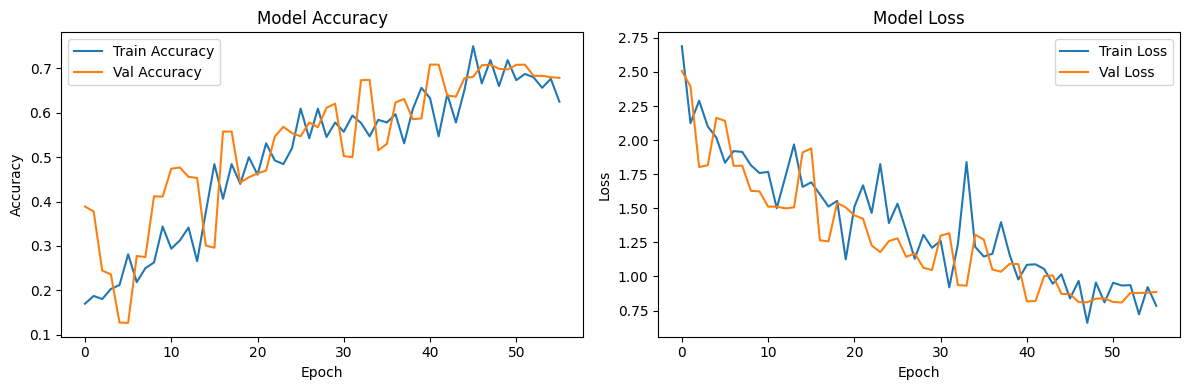

Training complete!


In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],     label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_history.png'))
plt.show()
print('Training complete!')